# Sales Performance Analysis
###TASK - 2

### Alfido Tech – Data Analytics Internship

## Project Introduction

Sales performance analysis helps businesses understand how their products perform, which regions generate higher sales, and how purchasing trends change over time...

This project focuses on analysing Superstore sales data to identify important sales patterns, evaluate product and regional performance, and understand customer purchasing trends.

Using Python and data analysis techniques, the project aims to transform raw sales records into meaningful business insights that can support better decision-making and sales planning...

The analysis also explores order patterns, customer segments, product categories, and shipping information to identify potential areas for business improvement.

## Project Objectives

The main objectives of this project are:

- Examine and prepare the sales dataset for reliable analysis
- Calculate key sales performance metrics, including total sales and average order value
- Analyse sales trends over time and identify seasonal patterns.
- Compare sales performance across regions, product categories, and customer segments
- Identify the best-performing and lowest-performing products
- Examine shipping patterns to understand order delivery timelines.
- Develop five practical recommendations based on the findings

## Dataset Description

The dataset used in this project is the Superstore Sales dataset, obtained from Kaggle

It contains transactional records of customer orders, including order dates, shipping details, customer segments, geographical information, product categories, and sales values

The dataset provides an opportunity to examine sales performance across different business dimensions, such as time, region, product, and customer segment

**Dataset Source:** [Superstore Sales – Kaggle](https://www.kaggle.com/datasets/bhanupratapbiswas/superstore-sales)

**Key Data Dimensions:**
- Order and shipping information
- Customer and segment details
- Geographical information
- Product categories and sub-categories
- Sales transactions

## 1. Importing Required Libraries

The following Python libraries are used to support data manipulation, numerical calculations, statistical analysis, and data visualisation throughout the project....

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(file_name, encoding='latin1')

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Saving superstore_final_dataset (1).csv to superstore_final_dataset (1).csv
Dataset loaded successfully!
Dataset Shape: (9800, 18)


,Row_ID,Order_ID,Order_Date,Ship_Date,Ship_Mode,Customer_ID,Customer_Name,Segment,Country,City,State,Postal_Code,Region,Product_ID,Category,Sub_Category,Product_Name,Sales
0,1,CA-2017-152156,8/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,8/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/6/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O Donnel,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O Donnel,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold N Roll Cart System,22.3680


## 2. Understanding the Dataset

Before performing the analysis, the dataset structure is examined to understand its dimensions, column names, data types, and sample records. This initial inspection helps identify the nature of the available data and prepares it for further analysis...

In [ ]:
print("Dataset Information:")
print("-" * 50)

df.info()

print("\nDataset Dimensions:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

Dataset Information:
--------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9800 entries, 0 to 9799
Data columns (total 18 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row_ID         9800 non-null   int64  
 1   Order_ID       9800 non-null   object 
 2   Order_Date     9800 non-null   object 
 3   Ship_Date      9800 non-null   object 
 4   Ship_Mode      9800 non-null   object 
 5   Customer_ID    9800 non-null   object 
 6   Customer_Name  9800 non-null   object 
 7   Segment        9800 non-null   object 
 8   Country        9800 non-null   object 
 9   City           9800 non-null   object 
 10  State          9800 non-null   object 
 11  Postal_Code    9789 non-null   float64
 12  Region         9800 non-null   object 
 13  Product_ID     9800 non-null   object 
 14  Category       9800 non-null   object 
 15  Sub_Category   9800 non-null   object 
 16  Product_Name   9800 non-

## 3. Statistical Summary and Missing Value Analysis

This section examines the numerical characteristics of the dataset and identifies missing values across all columns. Descriptive statistics help understand the distribution of sales, while missing value analysis highlights areas that may require data preparation...

In [ ]:
print("Statistical Summary:")
display(df.describe())

print("\nMissing Values Analysis:")
missing_values = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100
})

display(missing_values[missing_values['Missing Values'] > 0])

Statistical Summary:


,Row_ID,Postal_Code,Sales
count,9800.000000,9789.000000,9800.000000
mean,4900.500000,55273.322403,230.769059
std,2829.160653,32041.223413,626.651875
min,1.000000,1040.000000,0.444000
25%,2450.750000,23223.000000,17.248000
50%,4900.500000,58103.000000,54.490000
75%,7350.250000,90008.000000,210.605000
max,9800.000000,99301.000000,22638.480000



Missing Values Analysis:


,Missing Values,Missing Percentage
Postal_Code,11,0.112245


In [ ]:
sales_mean = df['Sales'].mean()
sales_median = df['Sales'].median()
sales_mode = df['Sales'].mode()[0]

print("Sales Statistical Measures")
print("-" * 30)
print(f"Mean   : {sales_mean:.2f}")
print(f"Median : {sales_median:.2f}")
print(f"Mode   : {sales_mode:.2f}")

Sales Statistical Measures
------------------------------
Mean   : 230.77
Median : 54.49
Mode   : 12.96


## 4. Data Cleaning and Preprocessing

Data cleaning is performed to improve data consistency and prepare the dataset for reliable analysis. This includes handling missing values, converting date columns into the appropriate format, and checking for duplicate records...

In [ ]:
# Create a working copy of the dataset
df_clean = df.copy()

# Convert date columns into datetime format
df_clean['Order_Date'] = pd.to_datetime(
    df_clean['Order_Date'], format='%d/%m/%Y'
)

df_clean['Ship_Date'] = pd.to_datetime(
    df_clean['Ship_Date'], format='%d/%m/%Y'
)

# Check missing values
print("Missing Values:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

# Check duplicate records
print("\nDuplicate Rows:", df_clean.duplicated().sum())

# Verify date conversion
print("\nDate Column Data Types:")
print(df_clean[['Order_Date', 'Ship_Date']].dtypes)

print("\nData Cleaning Check Completed!")

Missing Values:
Postal_Code    11
dtype: int64

Duplicate Rows: 0

Date Column Data Types:
Order_Date    datetime64[ns]
Ship_Date     datetime64[ns]
dtype: object

Data Cleaning Check Completed!


In [ ]:
print("Order Date Range:")
print("Earliest:", df_clean['Order_Date'].min())
print("Latest:", df_clean['Order_Date'].max())

print("\nShip Date Range:")
print("Earliest:", df_clean['Ship_Date'].min())
print("Latest:", df_clean['Ship_Date'].max())

print("\nSample Date Records:")
display(df_clean[['Order_Date', 'Ship_Date']].head(10))

print("\nRecords Where Ship Date Is Earlier Than Order Date:")
display(
    df_clean[df_clean['Ship_Date'] < df_clean['Order_Date']]
)

Order Date Range:
Earliest: 2015-01-03 00:00:00
Latest: 2018-12-30 00:00:00

Ship Date Range:
Earliest: 2015-01-07 00:00:00
Latest: 2019-01-05 00:00:00

Sample Date Records:


,Order_Date,Ship_Date
0,2017-11-08,2017-11-11
1,2017-11-08,2017-11-11
2,2017-06-12,2017-06-16
3,2016-10-11,2016-10-18
4,2016-10-11,2016-10-18
5,2015-06-09,2015-06-14
6,2015-06-09,2015-06-14
7,2015-06-09,2015-06-14
8,2015-06-09,2015-06-14
9,2015-06-09,2015-06-14



Records Where Ship Date Is Earlier Than Order Date:


,Row_ID,Order_ID,Order_Date,Ship_Date,Ship_Mode,Customer_ID,Customer_Name,Segment,Country,City,State,Postal_Code,Region,Product_ID,Category,Sub_Category,Product_Name,Sales


In [ ]:
missing_postal = df_clean[df_clean['Postal_Code'].isnull()]

print("Records with Missing Postal Codes:", len(missing_postal))

display(
    missing_postal[['Row_ID', 'City', 'State', 'Region', 'Sales']]
)

Records with Missing Postal Codes: 11


,Row_ID,City,State,Region,Sales
2234,2235,Burlington,Vermont,East,205.03
5274,5275,Burlington,Vermont,East,715.20
8798,8799,Burlington,Vermont,East,1294.75
9146,9147,Burlington,Vermont,East,99.98
9147,9148,Burlington,Vermont,East,8.04
9148,9149,Burlington,Vermont,East,1564.29
9386,9387,Burlington,Vermont,East,79.92
9387,9388,Burlington,Vermont,East,12.28
9388,9389,Burlington,Vermont,East,542.94
9389,9390,Burlington,Vermont,East,2.04


In [ ]:
print("Total Records:", len(df_clean))
print("Unique Orders:", df_clean['Order_ID'].nunique())
print("Unique Customers:", df_clean['Customer_ID'].nunique())
print("Unique Products:", df_clean['Product_ID'].nunique())

print("\nRecords per Order:")
print(df_clean['Order_ID'].value_counts().head(10))

Total Records: 9800
Unique Orders: 4922
Unique Customers: 793
Unique Products: 1861

Records per Order:
Order_ID
CA-2018-100111    14
CA-2018-157987    12
US-2017-108504    11
CA-2017-165330    11
US-2016-126977    10
CA-2016-131338    10
CA-2017-105732    10
CA-2016-104346     9
CA-2016-158421     9
CA-2018-140949     9
Name: count, dtype: int64


In [ ]:
print("Unique Ship Modes:")
print(df_clean['Ship_Mode'].unique())

print("\nUnique Customer Segments:")
print(df_clean['Segment'].unique())

print("\nUnique Regions:")
print(df_clean['Region'].unique())

print("\nUnique Product Categories:")
print(df_clean['Category'].unique())

print("\nNumber of Sub-Categories:")
print(df_clean['Sub_Category'].nunique())

Unique Ship Modes:
['Second Class' 'Standard Class' 'First Class' 'Same Day']

Unique Customer Segments:
['Consumer' 'Corporate' 'Home Office']

Unique Regions:
['South' 'West' 'Central' 'East']

Unique Product Categories:
['Furniture' 'Office Supplies' 'Technology']

Number of Sub-Categories:
17


In [ ]:
print("Final Data Quality Check")
print("-" * 30)

print("Total Rows:", len(df_clean))
print("Total Columns:", df_clean.shape[1])

print("\nTotal Missing Values:", df_clean.isnull().sum().sum())
print("Total Duplicate Rows:", df_clean.duplicated().sum())

print("\nNegative Sales Records:",
      (df_clean['Sales'] < 0).sum())

print("Zero Sales Records:",
      (df_clean['Sales'] == 0).sum())

print("\nData Types:")
display(df_clean.dtypes)

Final Data Quality Check
------------------------------
Total Rows: 9800
Total Columns: 18

Total Missing Values: 11
Total Duplicate Rows: 0

Negative Sales Records: 0
Zero Sales Records: 0

Data Types:


,0
Row_ID,int64
Order_ID,object
Order_Date,datetime64[ns]
Ship_Date,datetime64[ns]
Ship_Mode,object
Customer_ID,object
Customer_Name,object
Segment,object
Country,object
City,object


### Data Quality Assessment – Summary

The dataset contains 9,800 records and 18 columns. The initial quality assessment identified 11 missing values in the Postal_Code column, with no exact duplicate records, negative sales values, or zero sales values...

Both date columns were successfully converted into datetime format. The missing postal codes were retained without modification because the remaining geographical information was available.

The cleaned dataset is now ready for exploratory data analysis...

## 5. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to examine sales data, identify patterns, and understand business performance across different dimensions.

This section explores overall sales performance, order-level trends, customer segments, product categories, and regional contributions using descriptive statistics and visualisations...

### Overall Sales Performance

This analysis examines the overall sales generated by the dataset and evaluates key performance indicators, including total sales, number of orders, number of customers, and average order value.

In [ ]:
# Calculate total sales for each order
order_sales = df_clean.groupby('Order_ID')['Sales'].sum()

# Calculate overall sales metrics
total_sales = df_clean['Sales'].sum()
total_orders = df_clean['Order_ID'].nunique()
total_customers = df_clean['Customer_ID'].nunique()
average_order_value = order_sales.mean()

print("Overall Sales Performance")
print("-" * 30)
print(f"Total Sales: {total_sales:,.2f}")
print(f"Total Orders: {total_orders:,}")
print(f"Total Customers: {total_customers:,}")
print(f"Average Order Value: {average_order_value:,.2f}")

Overall Sales Performance
------------------------------
Total Sales: 2,261,536.78
Total Orders: 4,922
Total Customers: 793
Average Order Value: 459.48


### Sales Performance by Product Category

This analysis compares total sales across product categories to identify which category contributes the most to overall sales...

In [ ]:
category_sales = (
    df_clean.groupby('Category')['Sales']
    .sum()
    .sort_values(ascending=False)
)

print("Sales by Product Category:")
display(category_sales)

Sales by Product Category:


,Sales
Category,
Technology,827455.8730
Furniture,728658.5757
Office Supplies,705422.3340


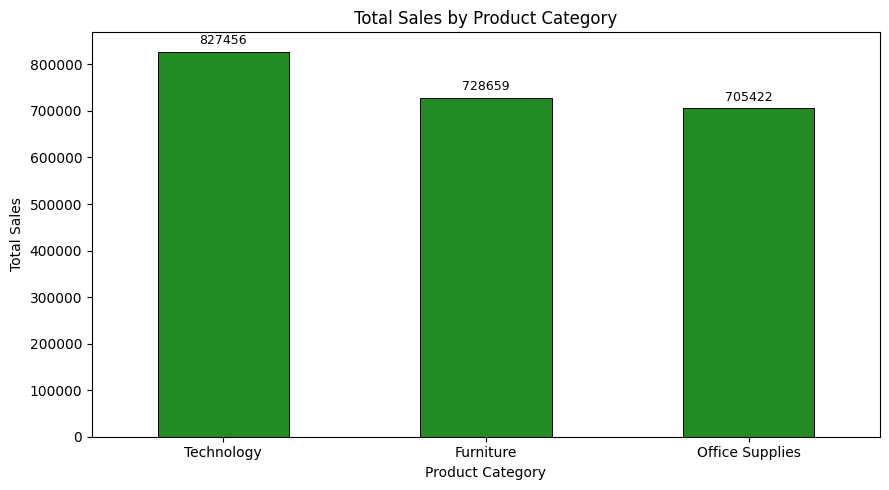

In [ ]:
plt.figure(figsize=(9, 5))

ax = category_sales.plot(
    kind='bar',
    color='forestgreen',
    edgecolor='black',
    linewidth=0.7
)

ax.set_title('Total Sales by Product Category')
ax.set_xlabel('Product Category')
ax.set_ylabel('Total Sales')
ax.tick_params(axis='x', rotation=0)

ax.bar_label(
    ax.containers[0],
    fmt='%.0f',
    padding=3,
    fontsize=9
)

plt.tight_layout()
plt.show()

**Observation:**

Technology recorded the highest total sales among the three product categories, followed by Furniture and Office Supplies. This indicates that Technology contributed the largest share of sales in the analysed dataset....

### Regional Sales Performance

This analysis compares total sales across the four geographical regions to identify differences in regional sales contributions.

In [ ]:
region_sales = (
    df_clean.groupby('Region')['Sales']
    .sum()
    .sort_values(ascending=False)
)

print("Sales by Region:")
display(region_sales)

Sales by Region:


,Sales
Region,
West,710219.6845
East,669518.7260
Central,492646.9132
South,389151.4590


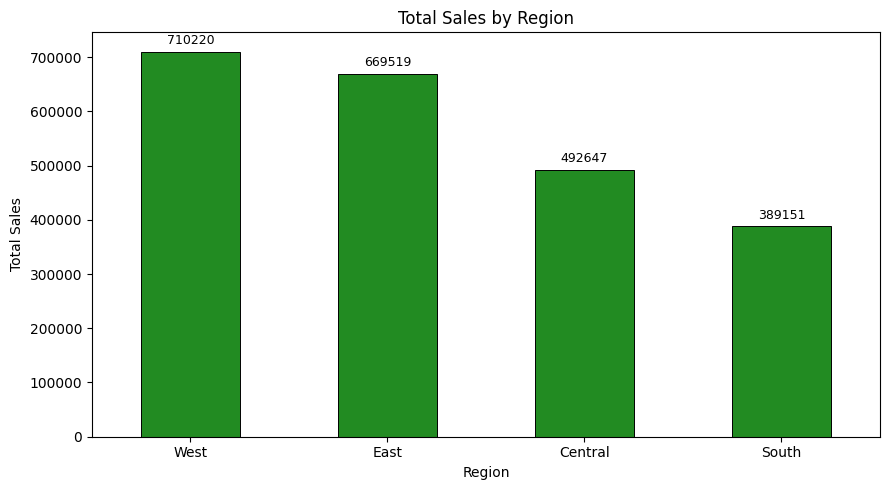

In [ ]:
plt.figure(figsize=(9, 5))

ax = region_sales.plot(
    kind='bar',
    color='forestgreen',
    edgecolor='black',
    linewidth=0.7
)

ax.set_title('Total Sales by Region')
ax.set_xlabel('Region')
ax.set_ylabel('Total Sales')
ax.tick_params(axis='x', rotation=0)

ax.bar_label(
    ax.containers[0],
    fmt='%.0f',
    padding=3,
    fontsize=9
)

plt.tight_layout()
plt.show()

**Observation:**

The West region recorded the highest total sales, followed by the East region. The Central region ranked third, while the South region reported the lowest sales. This highlights differences in sales contribution across the four geographical regions.

### Sales Performance by Customer Segment

This analysis examines sales across different customer segments to understand which segment contributes the most to overall sales.

In [ ]:
segment_sales = (
    df_clean.groupby('Segment')['Sales']
    .sum()
    .sort_values(ascending=False)
)

In [ ]:
pd.options.display.float_format = '{:,.2f}'.format

print("Sales by Customer Segment:")
display(segment_sales)

Sales by Customer Segment:


,Sales
Segment,
Consumer,"1,148,060.53"
Corporate,"688,494.07"
Home Office,"424,982.18"


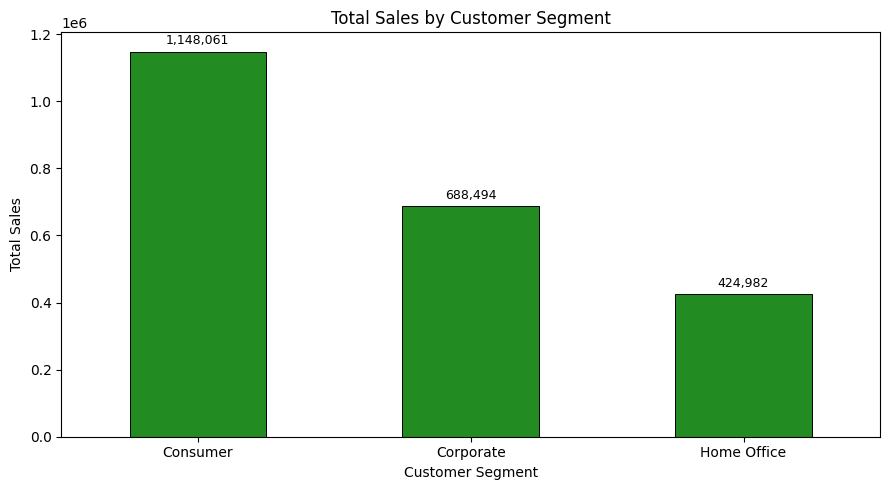

In [ ]:
plt.figure(figsize=(9, 5))

ax = segment_sales.plot(
    kind='bar',
    color='forestgreen',
    edgecolor='black',
    linewidth=0.7
)

ax.set_title('Total Sales by Customer Segment')
ax.set_xlabel('Customer Segment')
ax.set_ylabel('Total Sales')
ax.tick_params(axis='x', rotation=0)

ax.bar_label(
    ax.containers[0],
    fmt='{:,.0f}',
    padding=3,
    fontsize=9
)

plt.tight_layout()
plt.show()

**Observation:**

The Consumer segment generated the highest total sales, followed by the Corporate segment. The Home Office segment recorded the lowest sales. This indicates that the Consumer segment was the largest sales contributor among the three customer segments.

### Monthly Sales Trend Analysis

This analysis examines monthly sales over the available period to identify changes in sales performance over time. The Order_Date column is used to group sales transactions by month.

In [ ]:
# Aggregate sales by month
monthly_sales = (
    df_clean
    .set_index('Order_Date')
    .resample('ME')['Sales']
    .sum()
)

print("Monthly Sales Summary:")
display(monthly_sales.head(12))

Monthly Sales Summary:


,Sales
Order_Date,
2015-01-31,"14,205.71"
2015-02-28,"4,519.89"
2015-03-31,"55,205.80"
2015-04-30,"27,906.85"
2015-05-31,"23,644.30"
2015-06-30,"34,322.94"
2015-07-31,"33,781.54"
2015-08-31,"27,117.54"
2015-09-30,"81,623.53"


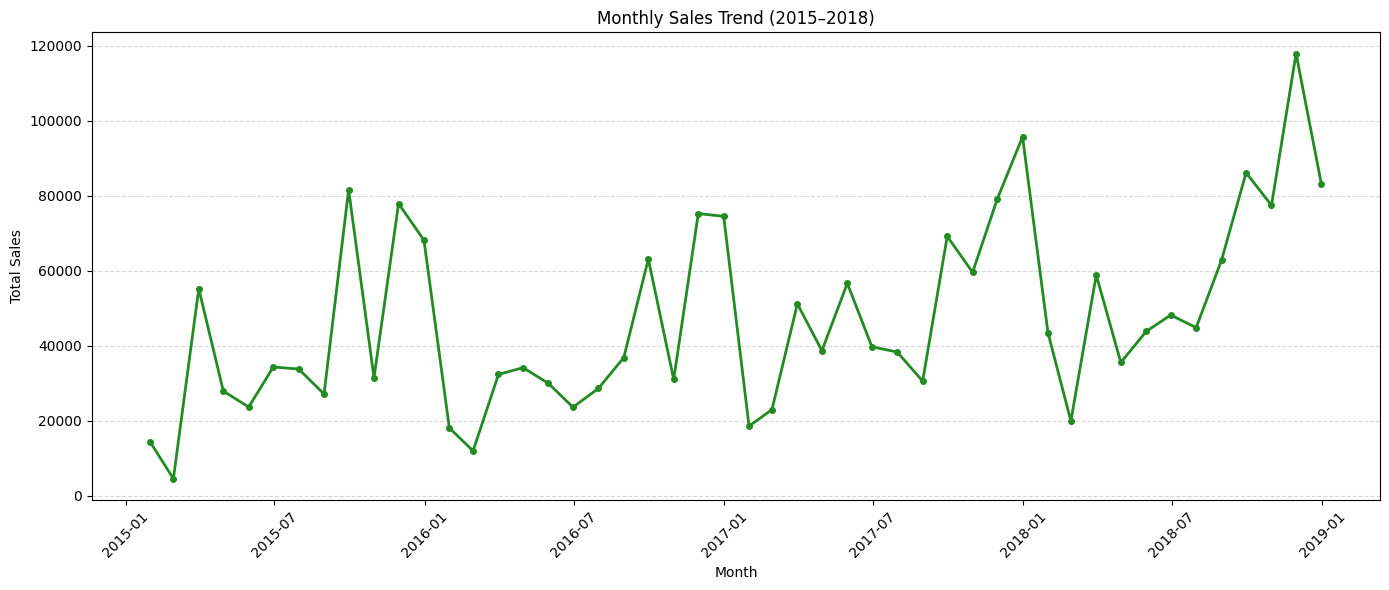

In [ ]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    color='forestgreen',
    linewidth=2,
    marker='o',
    markersize=4
)

plt.title('Monthly Sales Trend (2015–2018)')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
print("Highest Sales Month:")
print(monthly_sales.idxmax().strftime('%B %Y'))
print(f"Sales: {monthly_sales.max():,.2f}")

print("\nLowest Sales Month:")
print(monthly_sales.idxmin().strftime('%B %Y'))
print(f"Sales: {monthly_sales.min():,.2f}")

Highest Sales Month:
November 2018
Sales: 117,938.15

Lowest Sales Month:
February 2015
Sales: 4,519.89


**Key Findings:**

- November 2018 recorded the highest monthly sales of 117,938.15.
- February 2015 recorded the lowest monthly sales of 4,519.89.
- Monthly sales fluctuated considerably throughout the analysed period, indicating variations in sales performance over time.

### Year-wise Sales Performance

This analysis compares annual sales across the four years covered by the dataset to examine changes in overall sales performance.

In [ ]:
yearly_sales = (
    df_clean.groupby(df_clean['Order_Date'].dt.year)['Sales']
    .sum()
)

print("Year-wise Sales:")
display(yearly_sales)

Year-wise Sales:


,Sales
Order_Date,
2015,"479,856.21"
2016,"459,436.01"
2017,"600,192.55"
2018,"722,052.02"


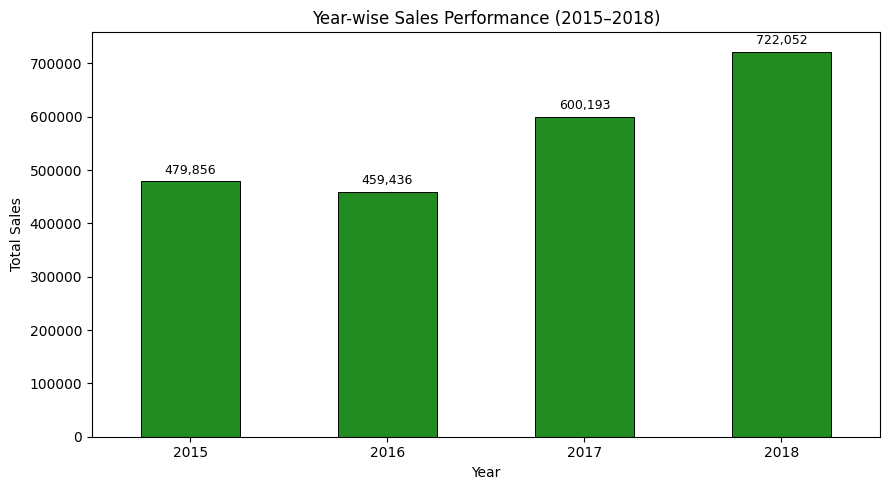

In [ ]:
plt.figure(figsize=(9, 5))

ax = yearly_sales.plot(
    kind='bar',
    color='forestgreen',
    edgecolor='black',
    linewidth=0.7
)

ax.set_title('Year-wise Sales Performance (2015–2018)')
ax.set_xlabel('Year')
ax.set_ylabel('Total Sales')
ax.tick_params(axis='x', rotation=0)

ax.bar_label(
    ax.containers[0],
    fmt='{:,.0f}',
    padding=3,
    fontsize=9
)

plt.tight_layout()
plt.show()

**Observation:**

Annual sales declined slightly in 2016 compared with 2015. However, sales increased in 2017 and continued to grow in 2018. The highest annual sales were recorded in 2018, indicating an improvement in sales performance during the final two years of the analysed period.

### Sales Distribution Across Product Sub-Categories

This analysis examines the distribution of total sales across the 17 product sub-categories. A treemap is used to compare their relative sales contributions and highlight the major and minor sales-generating groups.

In [ ]:
!pip install squarify

In [ ]:
subcategory_sales = (
    df_clean.groupby('Sub_Category')['Sales']
    .sum()
    .sort_values(ascending=False)
)

print("Sales by Product Sub-Category:")
display(subcategory_sales)

Sales by Product Sub-Category:


,Sales
Sub_Category,
Phones,"327,782.45"
Chairs,"322,822.73"
Storage,"219,343.39"
Tables,"202,810.63"
Binders,"200,028.79"
Machines,"189,238.63"
Accessories,"164,186.70"
Copiers,"146,248.09"
Bookcases,"113,813.20"


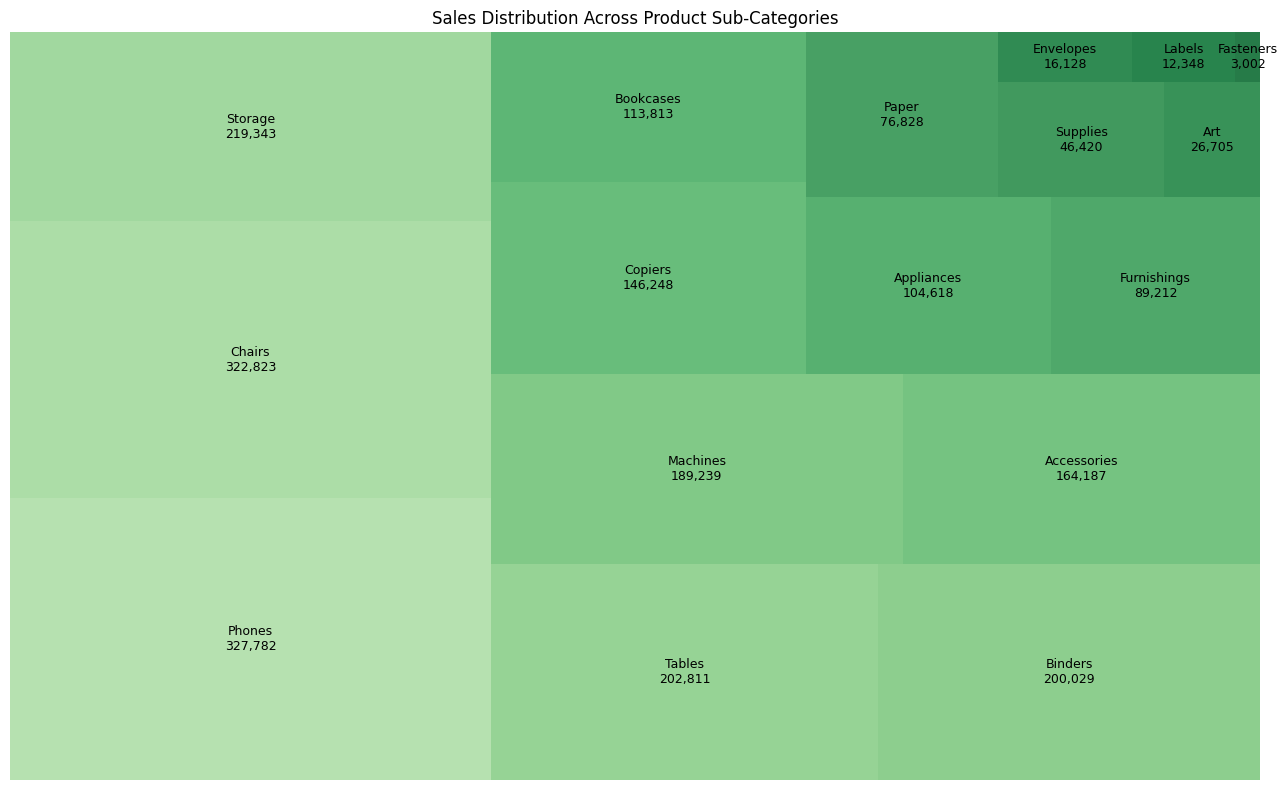

In [ ]:
import squarify

plt.figure(figsize=(13, 8))

labels = [
    f"{name}\n{value:,.0f}"
    for name, value in subcategory_sales.items()
]

squarify.plot(
    sizes=subcategory_sales.values,
    label=labels,
    alpha=0.85,
    color=plt.cm.Greens(
        np.linspace(0.35, 0.9, len(subcategory_sales))
    ),
    text_kwargs={'fontsize': 9}
)

plt.title('Sales Distribution Across Product Sub-Categories')
plt.axis('off')
plt.tight_layout()
plt.show()

**Observation:**

Phones recorded the highest sales among all product sub-categories, closely followed by Chairs. Storage and Tables also contributed substantially to overall sales. In contrast, Fasteners generated the lowest sales, followed by Labels and Envelopes. The treemap highlights the concentration of sales in a few major sub-categories and the relatively smaller contribution of several others.

### Shipping Time Analysis

This analysis examines the time taken to ship customer orders by comparing the order date with the shipping date. It calculates the delivery duration in days and compares average shipping time across different shipping modes to understand differences in order fulfilment timelines...

In [ ]:
df_clean['Shipping_Days'] = (
    df_clean['Ship_Date'] - df_clean['Order_Date']
).dt.days

print("Shipping Duration Summary:")
print(df_clean['Shipping_Days'].describe())

print("\nAverage Shipping Days by Shipping Mode:")
shipping_analysis = (
    df_clean.groupby('Ship_Mode')['Shipping_Days']
    .mean()
    .sort_values()
)

display(shipping_analysis)

Shipping Duration Summary:
count   9,800.00
mean        3.96
std         1.75
min         0.00
25%         3.00
50%         4.00
75%         5.00
max         7.00
Name: Shipping_Days, dtype: float64

Average Shipping Days by Shipping Mode:


,Shipping_Days
Ship_Mode,
Same Day,0.04
First Class,2.18
Second Class,3.25
Standard Class,5.01


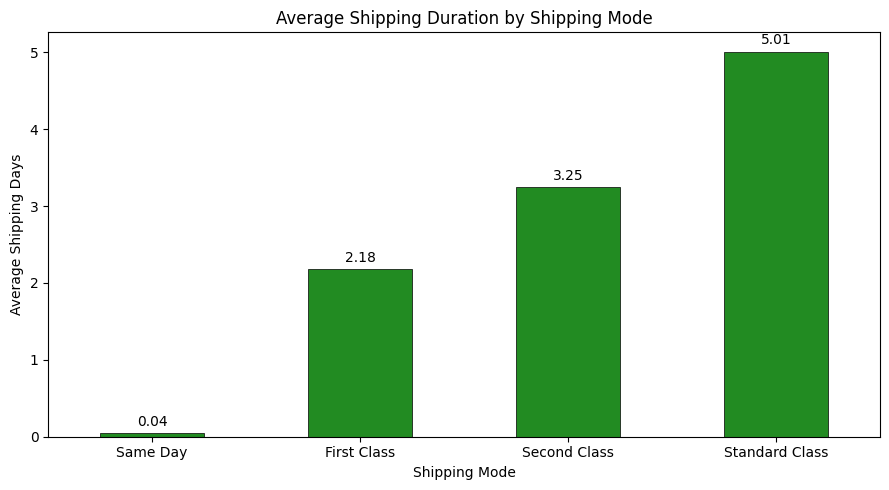

In [ ]:
plt.figure(figsize=(9, 5))

ax = shipping_analysis.plot(
    kind='bar',
    color='forestgreen',
    edgecolor='black',
    linewidth=0.5
)

plt.title('Average Shipping Duration by Shipping Mode')
plt.xlabel('Shipping Mode')
plt.ylabel('Average Shipping Days')
plt.xticks(rotation=0)

for container in ax.containers:
    ax.bar_label(container, fmt='%.2f', padding=3)

plt.tight_layout()
plt.show()

**Observation:**

Same Day shipping recorded the lowest average shipping duration at 0.04 days, followed by First Class at 2.18 days and Second Class at 3.25 days. Standard Class had the highest average shipping duration at 5.01 days. The results show a clear difference in fulfilment timelines across shipping modes, with Standard Class taking the longest on average...

### Top 10 Products by Sales

This analysis identifies the ten products with the highest total sales value. Sales are aggregated at the product level to compare their contribution and highlight the leading products in the dataset.

In [ ]:
top_products = (
    df_clean.groupby('Product_Name')['Sales']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_products)

,Sales
Product_Name,
Canon imageCLASS 2200 Advanced Copier,"61,599.82"
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,"27,453.38"
Cisco TelePresence System EX90 Videoconferencing Unit,"22,638.48"
HON 5400 Series Task Chairs for Big and Tall,"21,870.58"
GBC DocuBind TL300 Electric Binding System,"19,823.48"
GBC Ibimaster 500 Manual ProClick Binding System,"19,024.50"
Hewlett Packard LaserJet 3310 Copier,"18,839.69"
HP Designjet T520 Inkjet Large Format Printer - 24 Color,"18,374.90"
GBC DocuBind P400 Electric Binding System,"17,965.07"


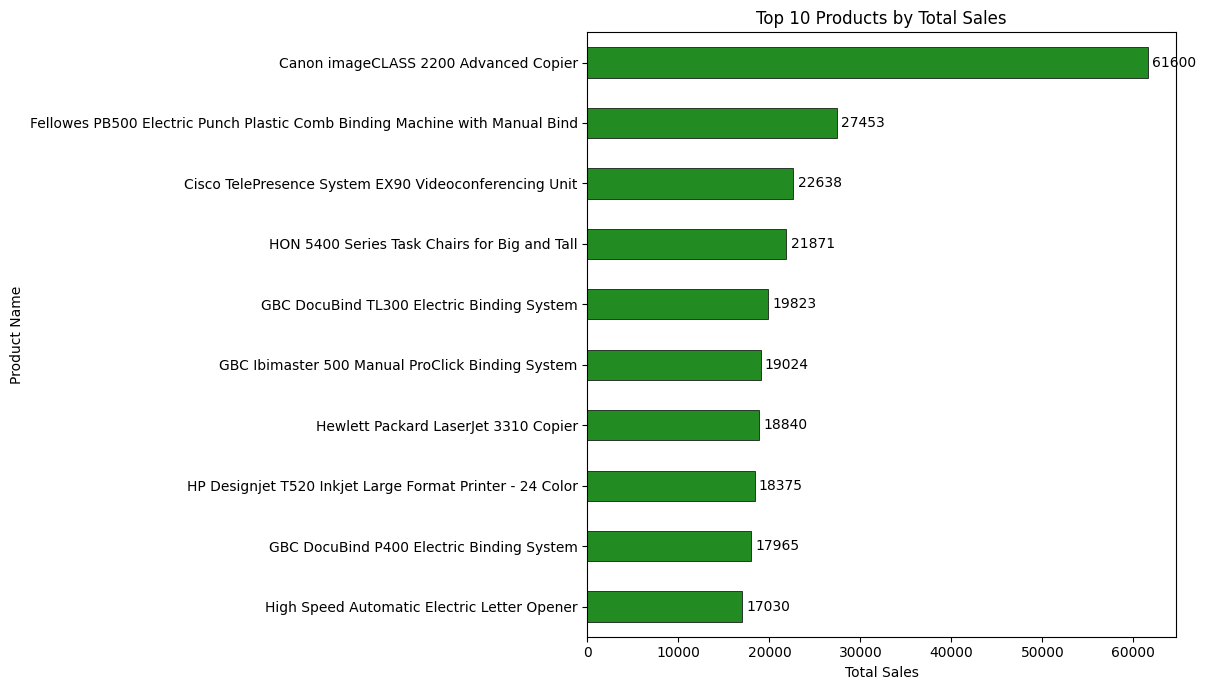

In [ ]:
plt.figure(figsize=(12, 7))

ax = top_products.sort_values().plot(
    kind='barh',
    color='forestgreen',
    edgecolor='black',
    linewidth=0.5
)

plt.title('Top 10 Products by Total Sales')
plt.xlabel('Total Sales')
plt.ylabel('Product Name')

for container in ax.containers:
    ax.bar_label(container, fmt='%.0f', padding=3)

plt.tight_layout()
plt.show()

**Observation:**

Canon imageCLASS 2200 Advanced Copier recorded the highest sales among the top 10 products, with total sales of 61,599.82. The second-highest product was the Fellowes PB500 Electric Punch Binding Machine, with sales of 27,453.38. The difference between the top two products indicates that the leading product generated substantially higher sales than the remaining products in this group. Several binding machines and printing-related products also appeared in the top 10...

### Customer-Level Sales Analysis

This analysis examines sales contributions at the customer level to identify the highest sales-generating customers. Total sales are aggregated for each customer to understand how sales are distributed across the customer base.

In [ ]:
customer_sales = (
    df_clean.groupby('Customer_Name')['Sales']
    .sum()
    .sort_values(ascending=False)
)

print("Total Unique Customers:", customer_sales.count())
print("\nTop 10 Customers by Sales:")

display(customer_sales.head(10))

Total Unique Customers: 793

Top 10 Customers by Sales:


,Sales
Customer_Name,
Sean Miller,"25,043.05"
Tamara Chand,"19,052.22"
Raymond Buch,"15,117.34"
Tom Ashbrook,"14,595.62"
Adrian Barton,"14,473.57"
Ken Lonsdale,"14,175.23"
Sanjit Chand,"14,142.33"
Hunter Lopez,"12,873.30"
Sanjit Engle,"12,209.44"


In [ ]:
top_10_customer_sales = customer_sales.head(10)

top_10_contribution = (
    top_10_customer_sales.sum() / total_sales
) * 100

print(f"Top 10 Customers' Total Sales: {top_10_customer_sales.sum():,.2f}")
print(f"Contribution to Overall Sales: {top_10_contribution:.2f}%")

Top 10 Customers' Total Sales: 153,811.17
Contribution to Overall Sales: 6.80%


In [ ]:
customer_contribution = customer_sales.reset_index()
customer_contribution.columns = ['Customer_Name', 'Sales']

customer_contribution['Sales_Contribution_%'] = (
    customer_contribution['Sales'] / total_sales
) * 100

customer_contribution['Cumulative_Contribution_%'] = (
    customer_contribution['Sales_Contribution_%'].cumsum()
)

print("Customer Contribution Analysis:")
display(customer_contribution.head(15))

Customer Contribution Analysis:


,Customer_Name,Sales,Sales_Contribution_%,Cumulative_Contribution_%
0,Sean Miller,"25,043.05",1.11,1.11
1,Tamara Chand,"19,052.22",0.84,1.95
2,Raymond Buch,"15,117.34",0.67,2.62
3,Tom Ashbrook,"14,595.62",0.65,3.26
4,Adrian Barton,"14,473.57",0.64,3.90
5,Ken Lonsdale,"14,175.23",0.63,4.53
6,Sanjit Chand,"14,142.33",0.63,5.16
7,Hunter Lopez,"12,873.30",0.57,5.72
8,Sanjit Engle,"12,209.44",0.54,6.26
9,Christopher Conant,"12,129.07",0.54,6.80


In [ ]:
top_30_sales = customer_sales.head(30)

remaining_sales = customer_sales.iloc[30:].sum()

pareto_data = pd.concat([
    top_30_sales,
    pd.Series({'Remaining Customers': remaining_sales})
])

pareto_contribution = (pareto_data / total_sales) * 100
cumulative_contribution = pareto_contribution.cumsum()

print("Top 30 Customers' Contribution:",
      f"{pareto_contribution.iloc[:30].sum():.2f}%")

print("Remaining Customers' Contribution:",
      f"{pareto_contribution.iloc[-1]:.2f}%")

print("Total Contribution:",
      f"{pareto_contribution.sum():.2f}%")

Top 30 Customers' Contribution: 15.64%
Remaining Customers' Contribution: 84.36%
Total Contribution: 100.00%


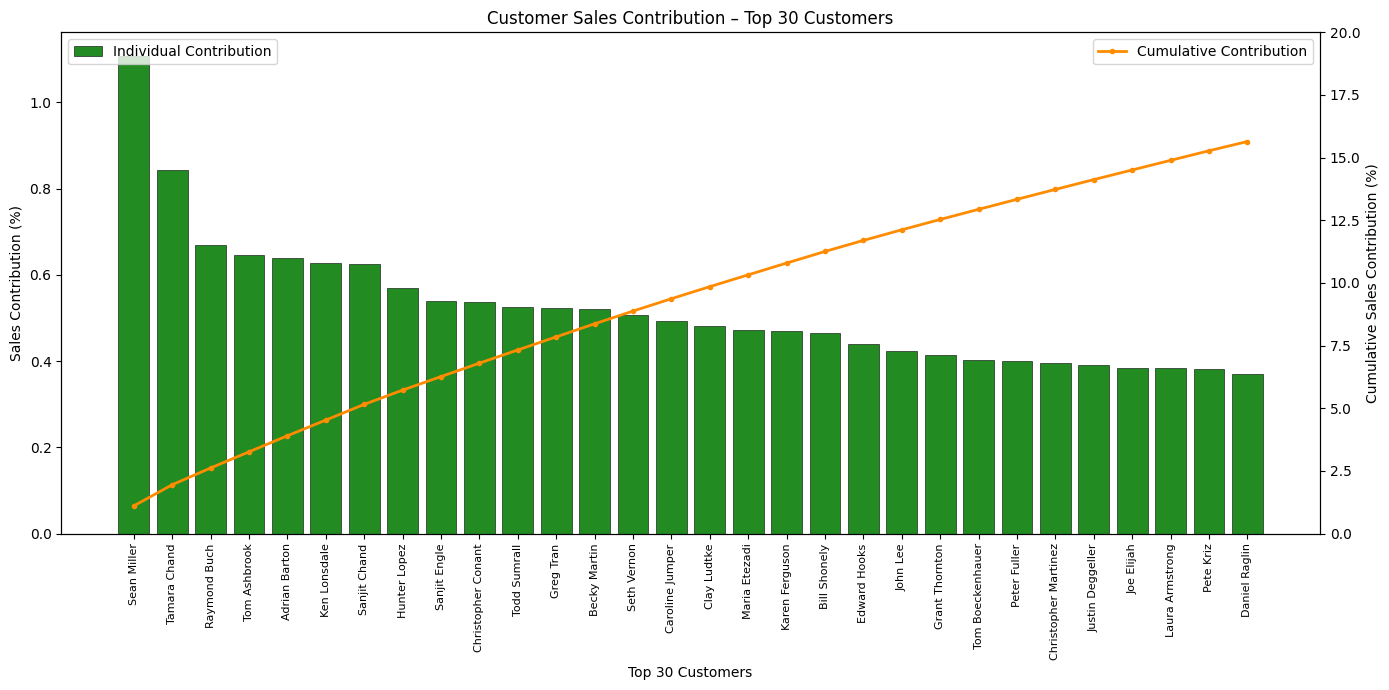

In [ ]:
fig, ax1 = plt.subplots(figsize=(14, 7))

x = np.arange(len(top_30_sales))

ax1.bar(
    x,
    (top_30_sales / total_sales) * 100,
    color='forestgreen',
    edgecolor='black',
    linewidth=0.4,
    label='Individual Contribution'
)

ax1.set_xlabel('Top 30 Customers')
ax1.set_ylabel('Sales Contribution (%)')
ax1.set_title('Customer Sales Contribution – Top 30 Customers')

ax1.set_xticks(x)
ax1.set_xticklabels(top_30_sales.index, rotation=90, fontsize=8)

ax2 = ax1.twinx()

ax2.plot(
    x,
    cumulative_contribution.iloc[:30].values,
    color='darkorange',
    marker='o',
    markersize=3,
    linewidth=2,
    label='Cumulative Contribution'
)

ax2.set_ylabel('Cumulative Sales Contribution (%)')
ax2.set_ylim(0, 20)

ax1.legend(loc='upper left')
ax2.legend(loc='upper right')

plt.tight_layout()
plt.show()

**Observation:**

The Pareto analysis shows that the top 30 customers collectively contribute 15.64% of total sales, while the remaining 763 customers account for 84.36%. Sean Miller is the highest sales-contributing customer, but individual customer contributions remain relatively small compared with overall sales. This indicates that the dataset's sales are distributed across a broad customer base rather than being concentrated among a small group of customers....

### Regional Sales and Customer Distribution Analysis

This analysis compares sales contribution with the number of unique customers across different regions. It helps examine whether regions with a larger customer base also generate higher sales, or whether sales contribution varies independently of customer count.

In [ ]:
regional_analysis = df_clean.groupby('Region').agg(
    Total_Sales=('Sales', 'sum'),
    Unique_Customers=('Customer_ID', 'nunique')
)

regional_analysis['Sales_Contribution_%'] = (
    regional_analysis['Total_Sales'] / total_sales
) * 100

regional_analysis['Customer_Contribution_%'] = (
    regional_analysis['Unique_Customers'] / total_customers
) * 100

display(regional_analysis.sort_values('Total_Sales', ascending=False))

,Total_Sales,Unique_Customers,Sales_Contribution_%,Customer_Contribution_%
Region,,,,
West,"710,219.68",681,31.40,85.88
East,"669,518.73",669,29.60,84.36
Central,"492,646.91",626,21.78,78.94
South,"389,151.46",509,17.21,64.19


In [ ]:
print("Sum of regional unique customer counts:",
      regional_analysis['Unique_Customers'].sum())

print("Overall unique customers:",
      total_customers)

print("\nCustomers appearing in multiple regions:")

customer_region_count = (
    df_clean.groupby('Customer_ID')['Region'].nunique()
)

print((customer_region_count > 1).sum())

Sum of regional unique customer counts: 2485
Overall unique customers: 793

Customers appearing in multiple regions:
765


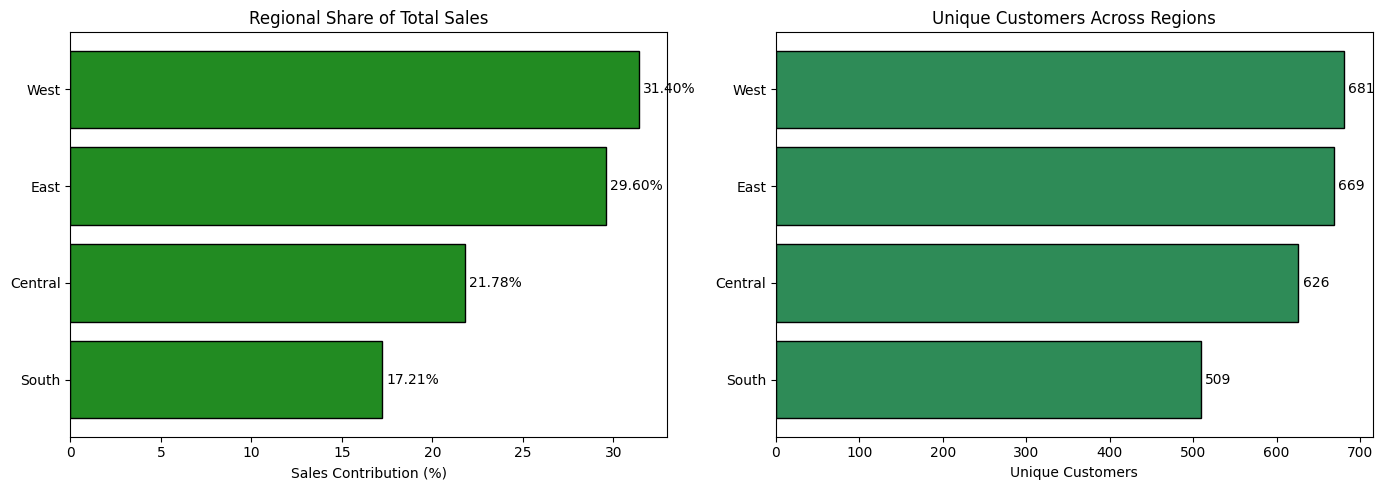

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

regional_plot = regional_analysis.sort_values('Total_Sales')

axes[0].barh(
    regional_plot.index,
    regional_plot['Sales_Contribution_%'],
    color='forestgreen',
    edgecolor='black'
)
axes[0].set_title('Regional Share of Total Sales')
axes[0].set_xlabel('Sales Contribution (%)')

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.2f%%', padding=3)

axes[1].barh(
    regional_plot.index,
    regional_plot['Unique_Customers'],
    color='seagreen',
    edgecolor='black'
)
axes[1].set_title('Unique Customers Across Regions')
axes[1].set_xlabel('Unique Customers')

for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%d', padding=3)

plt.tight_layout()
plt.show()

**Key Findings:**

- The West region generated the highest share of total sales at 31.40%, followed by the East region at 29.60%.
- The West and East regions also recorded the highest numbers of unique customers, with 681 and 669 respectively.
- The South region had the lowest sales contribution at 17.21% and the lowest regional unique customer count at 509.
- Regional customer counts overlap because many customers placed orders across multiple regions. Therefore, these counts should not be interpreted as mutually exclusive customer groups.

In [ ]:
final_kpis = {
    'Total Records': len(df_clean),
    'Unique Orders': df_clean['Order_ID'].nunique(),
    'Unique Customers': df_clean['Customer_ID'].nunique(),
    'Total Sales': df_clean['Sales'].sum(),
    'Average Order Value': order_sales.mean(),
    'Highest Sales Category': category_sales.idxmax(),
    'Highest Sales Region': region_sales.idxmax(),
    'Highest Sales Sub-Category': subcategory_sales.idxmax(),
    'Top-Selling Product': top_products.idxmax(),
    'Top Customer': customer_sales.idxmax(),
    'Average Shipping Days': df_clean['Shipping_Days'].mean(),
    'Top 10 Customers Sales Contribution (%)': top_10_contribution,
    'Top 30 Customers Sales Contribution (%)': pareto_contribution.iloc[:30].sum()
}

for metric, value in final_kpis.items():
    if isinstance(value, (int, float, np.integer, np.floating)):
        print(f"{metric}: {value:,.2f}")
    else:
        print(f"{metric}: {value}")

Total Records: 9,800.00
Unique Orders: 4,922.00
Unique Customers: 793.00
Total Sales: 2,261,536.78
Average Order Value: 459.48
Highest Sales Category: Technology
Highest Sales Region: West
Highest Sales Sub-Category: Phones
Top-Selling Product: Canon imageCLASS 2200 Advanced Copier
Top Customer: Sean Miller
Average Shipping Days: 3.96
Top 10 Customers Sales Contribution (%): 6.80
Top 30 Customers Sales Contribution (%): 15.64


## Executive Summary

This project analysed 9,800 records from the Superstore Sales dataset to understand sales performance across products, regions, customer segments, and shipping modes.

The dataset recorded total sales of 2,261,536.78 across 4,922 unique orders and 793 unique customers. The average order value was 459.48.

Technology was the highest-performing product category, while the West region generated the largest share of total sales at 31.40%. At the sub-category level, Phones recorded the highest sales, and the Canon imageCLASS 2200 Advanced Copier was the top-selling individual product by sales value.

Customer analysis showed that the top 30 customers contributed 15.64% of total sales, indicating that sales were distributed across a broad customer base. The average shipping duration was 3.96 days, with Standard Class having the longest average shipping duration among the four shipping modes.

Overall, the analysis highlights differences in product, regional, customer, and shipping performance. These findings provide a data-based foundation for identifying opportunities to improve sales planning, product strategy, and order fulfilment.

## Business Recommendations

Based on the findings of the sales analysis, the following recommendations can help businesses improve sales planning, product management, and order fulfilment.

**1. Strengthen Technology Category Sales**

Technology generated the highest sales among the three product categories. Businesses can focus on maintaining product availability, monitoring category-level performance, and identifying opportunities to expand sales of high-performing technology products.

**2. Review Regional Sales Strategies**

The West and East regions contributed the largest shares of total sales. Businesses can study the practices and product preferences in these regions and use the findings to improve sales strategies in lower-performing regions, particularly the South.

**3. Monitor High-Performing Products**

Phones and Chairs were the leading sub-categories by sales, while the Canon imageCLASS 2200 Advanced Copier was the top-selling individual product. Businesses can monitor the sales performance and availability of these products to support effective product planning.

**4. Improve Shipping and Fulfilment Planning**

Standard Class recorded the longest average shipping duration at 5.01 days. Businesses can review fulfilment processes and monitor delivery timelines across shipping modes to identify opportunities for operational improvement.

**5. Maintain Engagement Across the Customer Base**

The top 30 customers contributed only 15.64% of total sales, indicating a broad distribution of sales across customers. Businesses can focus on maintaining customer relationships through consistent service, targeted engagement, and suitable retention initiatives.

## Project Limitations

The analysis was performed using the available Superstore Sales dataset. Certain limitations should be considered while interpreting the findings:

- The dataset does not contain profit, cost, or discount information; therefore, profitability and profit margin could not be evaluated.
- Product quantity information is unavailable, so the analysis focuses on sales value rather than units sold.
- The dataset contains 11 missing values in the Postal_Code column. These values were retained without modification.
- The dataset represents historical Superstore transactions and should not be interpreted as actual sales data from Alfido Tech.
- The findings describe patterns in the available dataset and do not establish the causes behind sales or shipping differences.

## Conclusion

This project analysed Superstore sales data using Python and exploratory data analysis techniques. The analysis covered overall sales performance, product categories, sub-categories, geographical regions, customer segments, monthly and yearly trends, customer contributions, and shipping durations.

The findings identified Technology as the highest sales-generating category, the West as the leading region, and Phones as the top-performing sub-category. Customer analysis also highlighted a broad distribution of sales across the customer base, while shipping analysis revealed differences in fulfilment timelines across shipping modes.

Through data cleaning, statistical analysis, and meaningful visualisations, the project transformed raw transactional records into business insights and practical recommendations.

Overall, the project strengthened practical understanding of data analysis, data visualisation, and business-oriented interpretation of sales data....